In [ ]:

import pandas as pd
import glob

files = glob.glob('/content/*.csv')
print(files)

df = pd.read_csv(files[0])
print(df.head())
print("Total rows:", len(df))


['/content/ott_streaming_content_sample (2).csv']
             title     type    genre         country  release_year  \
0   City of Dreams    Movie    Drama           India          2020   
1      Laugh Track    Movie   Comedy   United States          2019   
2    Hidden Truths  TV Show    Crime  United Kingdom          2021   
3  Monsoon Letters    Movie  Romance           India          2022   
4   Galaxy Rangers  TV Show   Sci-Fi   United States          2023   

  content_rating   duration     platform  imdb_score  
0          TV-MA    132 min      Netflix         5.2  
1          PG-13     98 min  Prime Video         6.9  
2          TV-MA  2 Seasons      Netflix         8.6  
3          TV-14    116 min      Hotstar         5.7  
4          TV-14  3 Seasons  Prime Video         7.4  
Total rows: 120


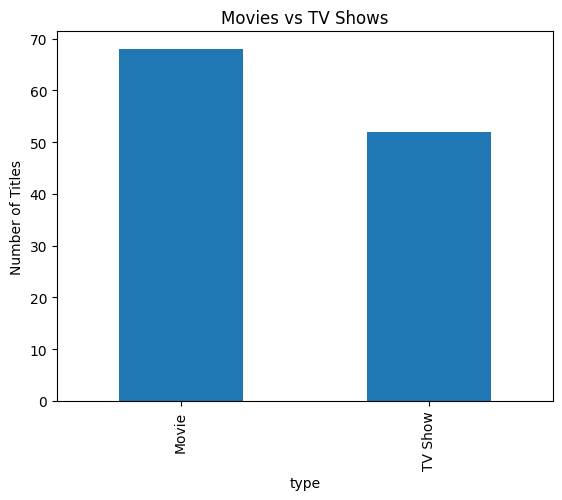

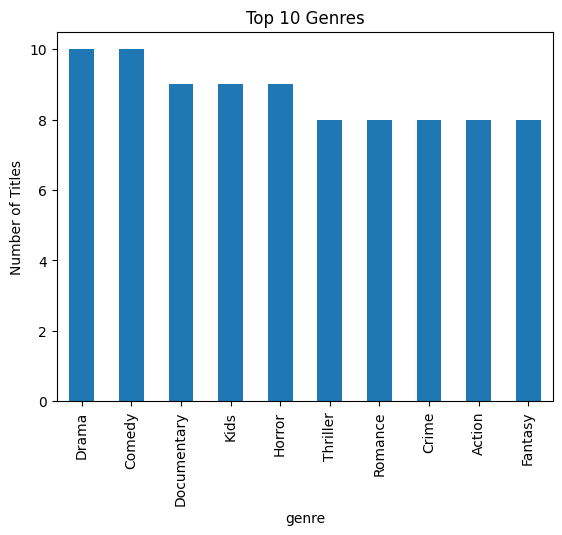

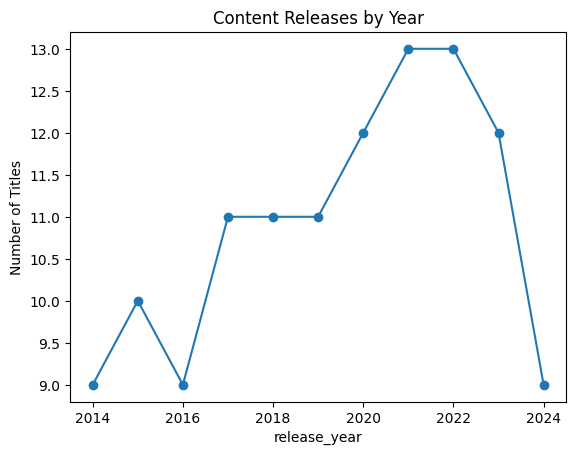

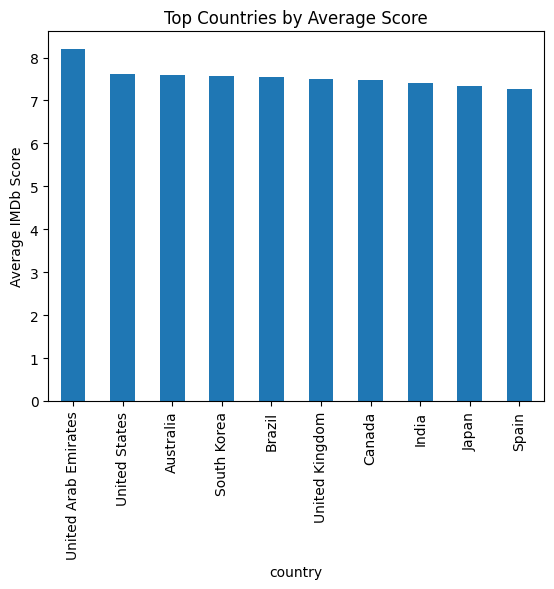

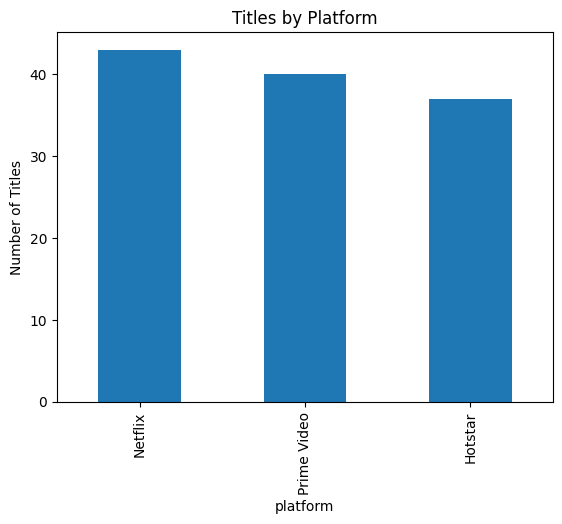

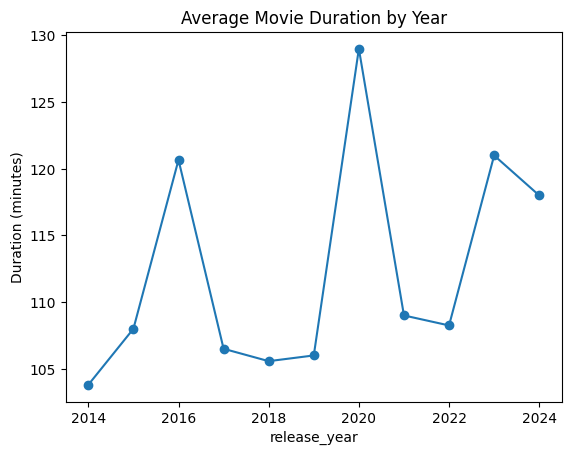

In [ ]:

import matplotlib.pyplot as plt
import pandas as pd

# Chart 1: Movies vs TV Shows
df["type"].value_counts().plot(kind="bar", title="Movies vs TV Shows")
plt.ylabel("Number of Titles")
plt.show()

# Chart 2: Top 10 Genres
df["genre"].value_counts().head(10).plot(kind="bar", title="Top 10 Genres")
plt.ylabel("Number of Titles")
plt.show()

# Chart 3: Releases by Year
df["release_year"].value_counts().sort_index().plot(
    kind="line", marker="o", title="Content Releases by Year"
)
plt.ylabel("Number of Titles")
plt.show()

# Chart 4: Average IMDb Score by Country
df.groupby("country")["imdb_score"].mean().sort_values(
    ascending=False
).head(10).plot(kind="bar", title="Top Countries by Average Score")
plt.ylabel("Average IMDb Score")
plt.show()

# Chart 5: Titles by Platform
df["platform"].value_counts().plot(kind="bar", title="Titles by Platform")
plt.ylabel("Number of Titles")
plt.show()

# Chart 6: Average Movie Duration
movies = df[df["type"] == "Movie"].copy()
movies["minutes"] = pd.to_numeric(
    movies["duration"].str.extract(r"(\d+)")[0], errors="coerce"
)
movies.groupby("release_year")["minutes"].mean().sort_index().plot(
    kind="line", marker="o", title="Average Movie Duration by Year"
)
plt.ylabel("Duration (minutes)")
plt.show()


SQL QUERIES

In [ ]:

# SQL Queries for OTT Streaming Content Analysis

sql_queries = """
-- 1. Titles by genre
SELECT genre, COUNT(*) AS total_titles
FROM OTT_Content
GROUP BY genre
ORDER BY total_titles DESC;

-- 2. Titles by platform
SELECT platform, COUNT(*) AS total_titles
FROM OTT_Content
GROUP BY platform;

-- 3. Content releases by year
SELECT release_year, COUNT(*) AS total_titles
FROM OTT_Content
GROUP BY release_year
ORDER BY release_year;

-- 4. Average IMDb score by country
SELECT country, ROUND(AVG(imdb_score), 2) AS avg_score
FROM OTT_Content
GROUP BY country
ORDER BY avg_score DESC;

-- 5. Movies vs TV Shows
SELECT type, COUNT(*) AS total_titles
FROM OTT_Content
GROUP BY type;
"""

print(sql_queries)



-- 1. Titles by genre
SELECT genre, COUNT(*) AS total_titles
FROM OTT_Content
GROUP BY genre
ORDER BY total_titles DESC;

-- 2. Titles by platform
SELECT platform, COUNT(*) AS total_titles
FROM OTT_Content
GROUP BY platform;

-- 3. Content releases by year
SELECT release_year, COUNT(*) AS total_titles
FROM OTT_Content
GROUP BY release_year
ORDER BY release_year;

-- 4. Average IMDb score by country
SELECT country, ROUND(AVG(imdb_score), 2) AS avg_score
FROM OTT_Content
GROUP BY country
ORDER BY avg_score DESC;

-- 5. Movies vs TV Shows
SELECT type, COUNT(*) AS total_titles
FROM OTT_Content
GROUP BY type;

